<a href="https://colab.research.google.com/github/pgarwol/MovieRecommender/blob/main/Projekt_bi_dane_Rmd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
install.packages("tidyverse")
install.packages("stevedata")
install.packages("survey")
install.packages("nonprobsvy")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘minqa’, ‘numDeriv’, ‘mitools’, ‘RcppArmadillo’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘zoo’, ‘miscTools’, ‘sandwich’, ‘iterators’, ‘operator.tools’, ‘maxLik’, ‘ncvreg’, ‘RANN’, ‘nleqslv’, ‘doParallel’, ‘foreach’, ‘formula.tools’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bitops’, ‘gtools’, ‘caTools’, ‘gplots’, ‘ROCR’, ‘shape’, ‘RcppEigen’, ‘nnls’, ‘gam’, ‘cvAUC’, ‘glmnet’, ‘SuperLearner’




In [8]:
install.packages("rpart")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



# A tibble: 12 × 6
   estimator      mean     bias  variance        mse type          
   <chr>         <dbl>    <dbl>     <dbl>      <dbl> <chr>         
 1 naive         8843. -13500.     17548. 182273677. bez duplikatów
 2 ipw          19364.  -2979.  24520385.  33395351. bez duplikatów
 3 reg          11020. -11323.     30125. 128243466. bez duplikatów
 4 misspec      22903.    559.     35739.    348527. bez duplikatów
 5 srs          22234.   -110.   1986800.   1998843. bez duplikatów
 6 superlearner 10969. -11374.     31905. 129404386. bez duplikatów
 7 naive         8858. -13507.     18426. 182447886. z duplikatami 
 8 ipw          18952.  -3412.  12966020.  24608554. z duplikatami 
 9 reg          11040. -11324.     29321. 128272506. z duplikatami 
10 misspec      22922.    558.     30654.    341465. z duplikatami 
11 srs          22446.     81.3  2202889.   2209496. z duplikatami 
12 superlearner 10988. -11376.     31349. 129441549. z duplikatami 


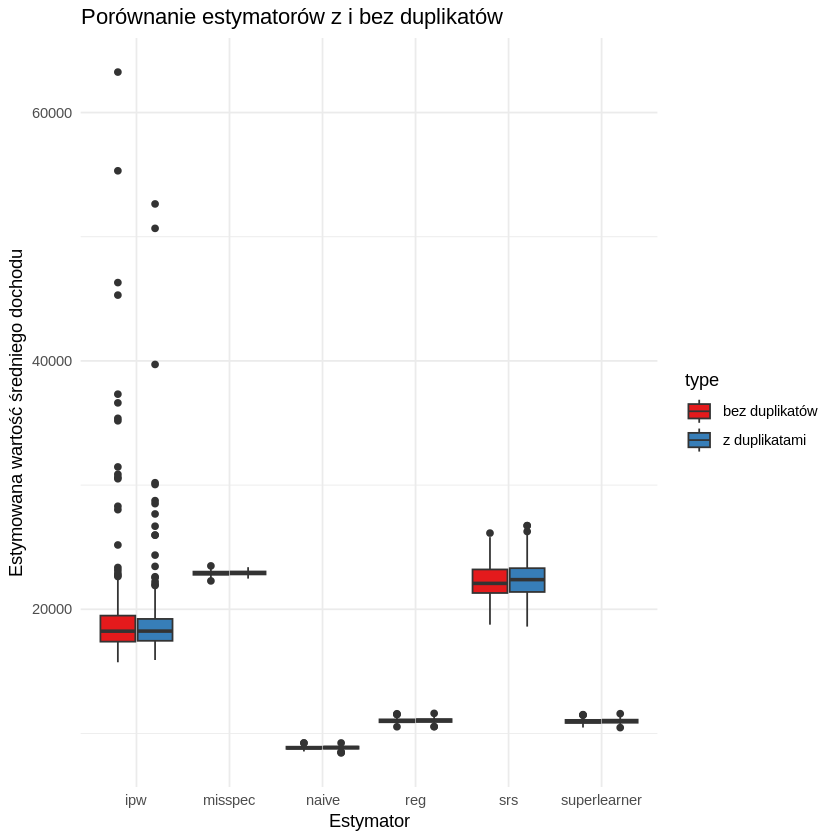

In [11]:
# 📚 Biblioteki
library(tidyverse)
library(stevedata)
library(survey)
library(nonprobsvy)
library(SuperLearner)
library(rpart)

# 🔢 Parametry
set.seed(2025)
B <- 300       # liczba replikacji
n <- 400       # próba nielosowa
n_r <- 400     # próba losowa
dup_ratio <- 0.1  # 10% duplikatów

# 📊 Funkcja podsumowania estymatora
summarise_estimator <- function(est_vec, true_val) {
  theta_hat <- mean(est_vec, na.rm = TRUE)
  bias <- theta_hat - true_val
  variance <- var(est_vec, na.rm = TRUE)
  mse <- bias^2 + variance
  c(mean = theta_hat, bias = bias, variance = variance, mse = mse)
}

# 🌀 Funkcja symulacyjna
run_simulation <- function(pop, B, with_duplicates = FALSE) {
  if (with_duplicates) {
    dup_n <- round(nrow(pop) * dup_ratio)
    pop <- bind_rows(pop, pop %>% slice_sample(n = dup_n, replace = TRUE))
  }

  theta_pop <- mean(pop$realrinc)

  results <- data.frame(
    naive = numeric(B),
    ipw = numeric(B),
    reg = numeric(B),
    misspec = numeric(B),
    srs = numeric(B),
    superlearner = numeric(B)
  )

  for (b in 1:B) {
    # Prawdopodobieństwa włączenia (dobrze określone)
    pop$incl_prob <- plogis(
      -2 + 0.02 * pop$age - 0.0001 * pop$realrinc +
        ifelse(pop$gender == "female", 0.4, 0) +
        0.05 * pop$childs
    )
    pop$in_sample <- rbinom(nrow(pop), 1, pop$incl_prob)
    sample_np <- pop %>% filter(in_sample == 1)

    # Naiwny
    results$naive[b] <- mean(sample_np$realrinc)

    # IPW
    ipw_weights <- 1 / sample_np$incl_prob
    results$ipw[b] <- weighted.mean(sample_np$realrinc, w = ipw_weights)

    # Regresyjny
    reg_model <- lm(realrinc ~ age + gender + educcat + wrkstat + occrecode + maritalcat + childs, data = sample_np)
    preds <- predict(reg_model, newdata = pop)
    results$reg[b] <- mean(preds)

    # Super Learner
    tryCatch({
      sl_fit <- SuperLearner(
        Y = sample_np$realrinc,
        X = sample_np %>% select(age, gender, educcat, wrkstat, occrecode, maritalcat, childs),
        newX = pop %>% select(age, gender, educcat, wrkstat, occrecode, maritalcat, childs),
        family = gaussian(),
        SL.library = c("SL.glm","SL.rpart", "SL.mean")
      )
      results$superlearner[b] <- mean(sl_fit$SL.predict)
    }, error = function(e) {
      results$superlearner[b] <- NA
    })

    # Misspecified
    pop$incl_prob_mis <- plogis(
      -1 + 0.01 * pop$age + 0.1 * as.numeric(pop$gender)
    )
    pop$in_sample_mis <- rbinom(nrow(pop), 1, pop$incl_prob_mis)
    sample_mis <- pop %>% filter(in_sample_mis == 1)
    results$misspec[b] <- mean(sample_mis$realrinc)

    # SRS
    sample_srs <- pop %>% sample_n(n_r)
    results$srs[b] <- mean(sample_srs$realrinc)
  }

  list(results = results, theta_pop = theta_pop)
}

# 🔍 Dane populacyjne
pop <- gss_wages %>%
  select(realrinc, age, gender, educcat, wrkstat, occrecode, maritalcat, childs) %>%
  drop_na() %>%
  mutate(
    gender = as.factor(gender),
    educcat = as.factor(educcat),
    wrkstat = as.factor(wrkstat),
    occrecode = as.factor(occrecode),
    maritalcat = as.factor(maritalcat)
  )

# ▶️ Symulacja
sim_clean <- run_simulation(pop, B, with_duplicates = FALSE)
sim_dup <- run_simulation(pop, B, with_duplicates = TRUE)

# 📋 Podsumowanie
summary_clean <- map_dfr(
  sim_clean$results,
  ~ summarise_estimator(.x, sim_clean$theta_pop),
  .id = "estimator"
) %>% mutate(type = "bez duplikatów")

summary_dup <- map_dfr(
  sim_dup$results,
  ~ summarise_estimator(.x, sim_dup$theta_pop),
  .id = "estimator"
) %>% mutate(type = "z duplikatami")

final_summary <- bind_rows(summary_clean, summary_dup)
print(final_summary)

# 📈 Wizualizacja
results_long <- bind_rows(
  sim_clean$results %>% mutate(type = "bez duplikatów"),
  sim_dup$results %>% mutate(type = "z duplikatami")
) %>%
  pivot_longer(cols = -type, names_to = "estimator", values_to = "estimate")

ggplot(results_long, aes(x = estimator, y = estimate, fill = type)) +
  geom_boxplot(position = position_dodge(width = 0.8)) +
  theme_minimal() +
  labs(title = "Porównanie estymatorów z i bez duplikatów",
       x = "Estymator", y = "Estymowana wartość średniego dochodu") +
  scale_fill_brewer(palette = "Set1")
